### ELO328 - Procesamiento Digital de Imágenes
# Clase 12: Autoencoders
Prof. Nicolás Torres<br/>
<a href="mailto:nicolas.torresr@usm.cl">nicolas.torresr@usm.cl</a><br/>
Ingeniería Civil Telemática<br/>
Departamento de Electrónica<br/>
Universidad Técnica Federico Santa María

# Autoencoders

Hacen que una red neuronal tenga como objetivo la reconstrucción de su propio input, es decir, los atributos utilizados
para entrenar la red son los mismos que la red debe poder predecir. La clave está en obligar a la red a reconstruir dicho input, pero a partir de una dimensionalidad menor a la de la entrada.

<div align="center">
    <img src="img/autoencoder.png" alt="" width="35%" align="center" />
</div>

# Arquitectura de los Autoencoders
Un Autoencoder consta de tres componentes principales: Encoder, Embedding, Decoder.

<div align="center">
    <img src="img/arquitectura-autoencoder.png" alt="" width="60%" align="center" />
</div>

<h3><b>Tipos de Autoencoders: </b></h3>

<div align="right">
    <img src="img/arquitecturas.png" alt="" width="60%" align="right" />
</div>

Vanilla Autoencoder;

Sparse Autoencoder;

Convolutional Autoencoder;

Denoising Autoencoder;

Variational Autoencoder;

etc...



In [1]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, losses
from tensorflow.keras.models import Model
from tensorflow.keras.datasets import fashion_mnist
from keras import Input
from keras.layers import Dense, LeakyReLU, BatchNormalization
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Cargar datos

In [2]:
(X_train, y_train), (X_test, y_test) = fashion_mnist.load_data()

X_train = X_train.astype('float32')/255.
X_test = X_test.astype('float32') /255.

print()
print(f"Shape of Train Data: {X_train.shape}")
print(f"Shape of Test Data: {X_test.shape}")


Shape of Train Data: (60000, 28, 28)
Shape of Test Data: (10000, 28, 28)


In [3]:
fashionMNIST_classes = {0:"T-shirt/top", 1:"Trouser",
                        2:"Pullover", 3:"Dress",
                        4:"Coat", 5:"Sandal",
                        6:"Shirt", 7:"Sneaker", 
                        8:"Bag", 9:"Ankle boot"}

#### **Sample Images**

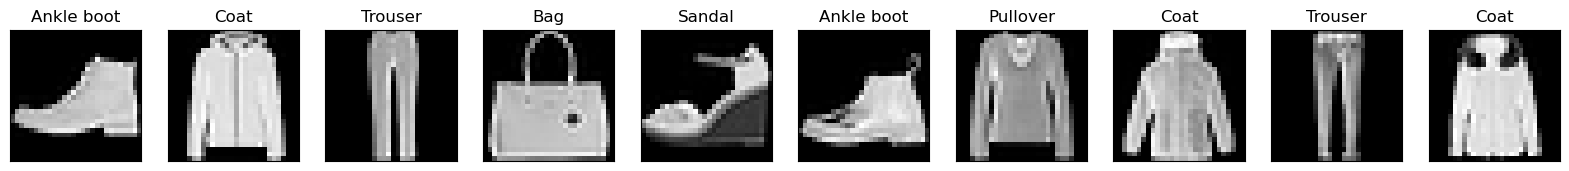

In [4]:
n = 10
plt.figure(figsize = (20, 4))
for i in range(n):
    plt.subplot(1, n, i+1)
    idx = np.random.randint(i, len(X_train))
    plt.imshow(X_train[idx])
    plt.title(fashionMNIST_classes[y_train[idx]])
    plt.gray()
    plt.xticks([]); plt.yticks([])
plt.show()

# Modelo I: Vanilla Autoencoder

In [5]:
EMBEDDING_DIM = 64

class MNIST_AutoEncoder(Model):
    def __init__(self, embedding_dim):
        super(MNIST_AutoEncoder, self).__init__()
        self.embedding_dim = embedding_dim

        # Building our Encoder
        self.encoder = tf.keras.Sequential([
            layers.Input(shape=(28, 28)), 
            layers.Flatten(),
            layers.Dense(self.embedding_dim, activation = "relu"),
        ])

        # Building our Decoder
        self.decoder = tf.keras.Sequential([
            layers.Input(shape=(self.embedding_dim)),
            layers.Dense(784, activation="sigmoid"),      
            layers.Reshape((28, 28))        
        ])

    def call(self, X):
        encoded = self.encoder(X)
        decoded = self.decoder(encoded)
        return decoded

In [6]:
vanillaAutoencoder = MNIST_AutoEncoder(EMBEDDING_DIM)
vanillaAutoencoder.compile(optimizer='adam', loss=losses.MeanSquaredError())

In [7]:
vanillaAutoencoder.encoder.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 flatten (Flatten)           (None, 784)               0         
                                                                 
 dense (Dense)               (None, 64)                50240     
                                                                 
Total params: 50,240
Trainable params: 50,240
Non-trainable params: 0
_________________________________________________________________


In [8]:
vanillaAutoencoder.decoder.summary()

Model: "sequential_1"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 dense_1 (Dense)             (None, 784)               50960     
                                                                 
 reshape (Reshape)           (None, 28, 28)            0         
                                                                 
Total params: 50,960
Trainable params: 50,960
Non-trainable params: 0
_________________________________________________________________


In [9]:
mnist_training_history = vanillaAutoencoder.fit(x = X_train, y = X_train,
                                       epochs = 10, 
                                       batch_size = 16,
                                       shuffle = True,
                                       validation_data = (X_test, X_test))

Epoch 1/10
3750/3750 [==============================] - 7s 2ms/step - loss: 0.0197 - val_loss: 0.0114
Epoch 2/10
3750/3750 [==============================] - 7s 2ms/step - loss: 0.0104 - val_loss: 0.0097
Epoch 3/10
3750/3750 [==============================] - 7s 2ms/step - loss: 0.0095 - val_loss: 0.0094
Epoch 4/10
3750/3750 [==============================] - 7s 2ms/step - loss: 0.0093 - val_loss: 0.0093
Epoch 5/10
3750/3750 [==============================] - 7s 2ms/step - loss: 0.0091 - val_loss: 0.0091
Epoch 6/10
3750/3750 [==============================] - 7s 2ms/step - loss: 0.0090 - val_loss: 0.0091
Epoch 7/10
3750/3750 [==============================] - 7s 2ms/step - loss: 0.0089 - val_loss: 0.0089
Epoch 8/10
3750/3750 [==============================] - 7s 2ms/step - loss: 0.0088 - val_loss: 0.0089
Epoch 9/10
3750/3750 [==============================] - 6s 2ms/step - loss: 0.0088 - val_loss: 0.0089
Epoch 10/10
3750/3750 [==============================] - 7s 2ms/step - loss: 0.008

#### **Results**

In [10]:
# Storing our training and validation losses
train_loss = mnist_training_history.history["loss"]
val_loss = mnist_training_history.history["val_loss"]
epochs = [d for d in range(1,11)]

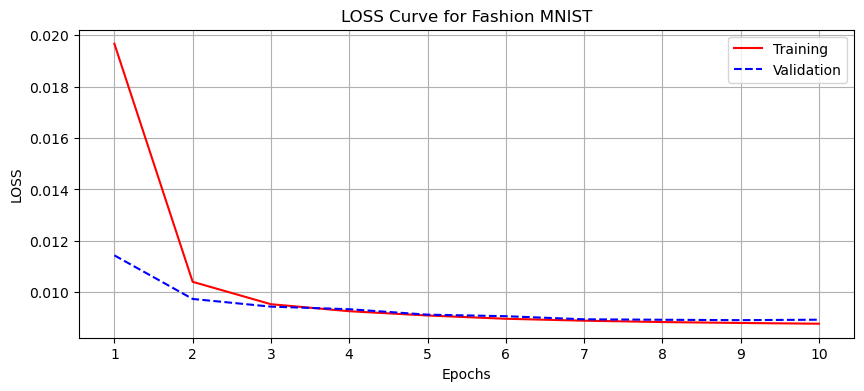

In [12]:
plt.figure(figsize=(10, 4))
plt.plot(epochs, train_loss, '-r', label="Training")
plt.plot(epochs, val_loss, '--b', label="Validation")
plt.title("LOSS Curve for Fashion MNIST")
plt.grid(True)
plt.xlabel('Epochs'); plt.ylabel("LOSS")
plt.legend()
plt.xticks([d for d in range(1, 11)])
plt.show();

In [13]:
# collecting the encoded and decoded versions of our test data
encoded_imgs = vanillaAutoencoder.encoder(X_test).numpy()
decoded_imgs = vanillaAutoencoder.decoder(encoded_imgs).numpy()

In [14]:
def plot_reconstructed_images(n = 10):
    # Plotting our original and reconstructed images
    plt.figure(figsize=(20, 4))
    for i in range(n):
        # To display the original images
        ax = plt.subplot(2, n, i + 1)
        idx = np.random.randint(i, len(X_test))
        plt.imshow(X_test[idx])
        plt.title("original")
        plt.gray()
        ax.get_xaxis().set_visible(False)
        ax.get_yaxis().set_visible(False)

        # To display reconstructed images
        ax = plt.subplot(2, n, i + 1 + n)
        plt.imshow(decoded_imgs[idx])
        plt.title("reconstructed")
        plt.gray()
        ax.get_xaxis().set_visible(False)
        ax.get_yaxis().set_visible(False)
    plt.show()

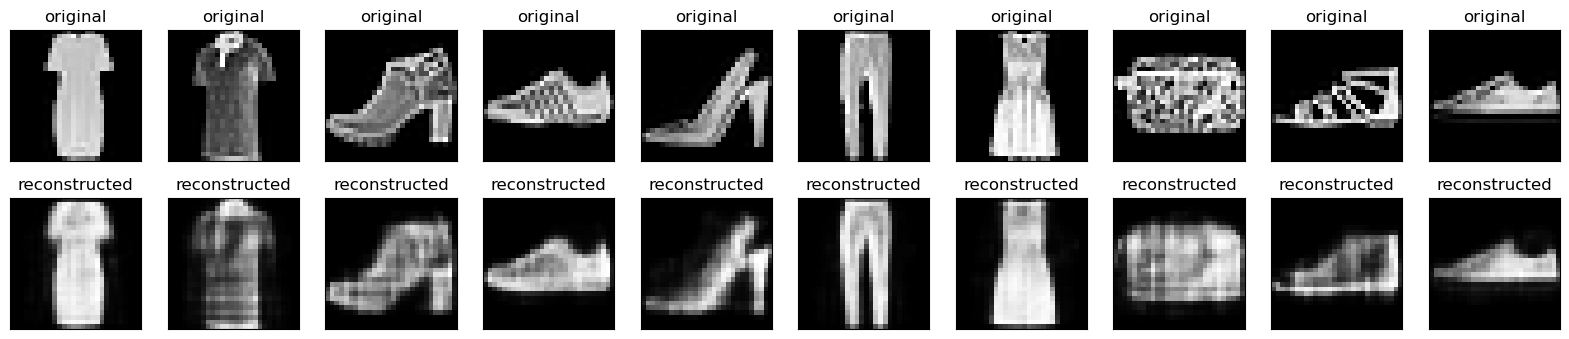

In [17]:
plot_reconstructed_images(n = 10)

# Denoising Autoencoders (DAE)

<div align="center">
    <img src="img/denoising.png" alt="" width="80%" align="center" />
</div>

In [18]:
# Cargar dataset de dígitos manuscritos
(X_train, y_train), (X_test, y_test) = keras.datasets.mnist.load_data()

In [19]:
print("X_train: ", X_train.shape)
print("y_train: ", y_train.shape)
print("X_test: ", X_test.shape)
print("y_test: ", y_test.shape)

X_train:  (60000, 28, 28)
y_train:  (60000,)
X_test:  (10000, 28, 28)
y_test:  (10000,)


In [20]:
# Normalizar (dividir por 255) los datos de entrada
X_train = X_train.astype("float32") / 255
X_test = X_test.astype("float32") / 255

# Visualizar algunos datos

In [21]:
n_digits = 10

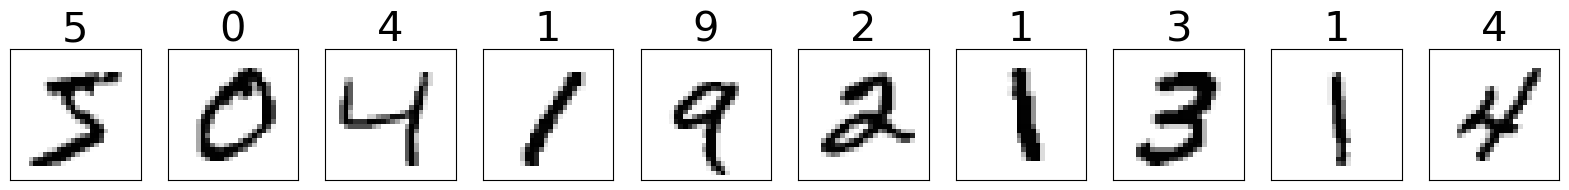

In [22]:
fig = plt.figure(figsize=(2*n_digits, 20))
for i in range(n_digits):
    ax = fig.add_subplot(n_digits, 10, i + 1, xticks=[], yticks=[])
    ax.imshow(X_train[i], cmap=plt.cm.binary)
    ax.set_title(y_train[i], fontsize=30)

# Añadir ruido a los datos

In [23]:
level_of_noise=0.5

In [24]:
# Añadir ruido aleatorio basado en una distribución Gaussiana
X_train_noisy = X_train + level_of_noise * np.random.normal(loc=0.0, scale=1.0, size=X_train.shape)
X_test_noisy = X_test + level_of_noise * np.random.normal(loc=0.0, scale=1.0, size=X_test.shape)

In [25]:
# Asegurarse que los valores estén entre 0 y 1
X_train_noisy = np.clip(X_train_noisy, 0., 1.)
X_test_noisy = np.clip(X_test_noisy, 0., 1.)

# Visualizar algunos datos con ruido

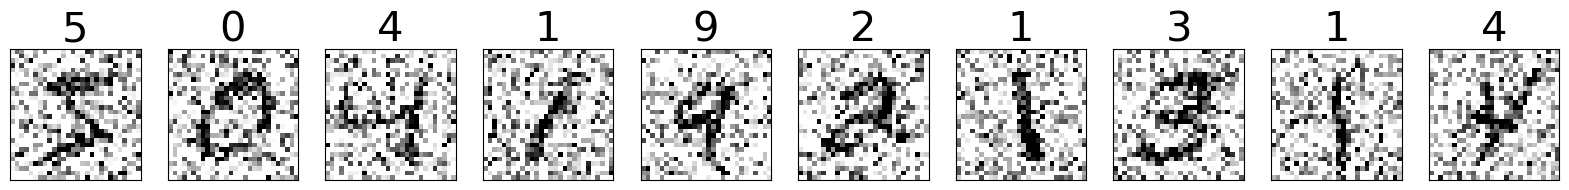

In [26]:
fig = plt.figure(figsize=(2*n_digits,20))
for i in range(n_digits):
    ax = fig.add_subplot(n_digits, 10, i + 1, xticks=[], yticks=[])
    ax.imshow(X_train_noisy[i], cmap=plt.cm.binary)
    ax.set_title(y_train[i], fontsize=30)

In [27]:
# Reshape a los datos
X_train = X_train.reshape(60000, 28*28)
X_test = X_test.reshape(10000, 28*28)
X_train_noisy = X_train_noisy.reshape(60000, 28*28)
X_test_noisy = X_test_noisy.reshape(10000, 28*28)

In [28]:
print("X_train: ", X_train.shape)
print("X_test: ", X_test.shape)
print("X_train_noisy: ", X_train_noisy.shape)
print("X_test_noisy: ", X_test_noisy.shape)

X_train:  (60000, 784)
X_test:  (10000, 784)
X_train_noisy:  (60000, 784)
X_test_noisy:  (10000, 784)


# Modelo II: DAE

## Configurar la red neuronal

In [29]:
#--- Definir tamaño
n_inputs = X_train.shape[1] # número de neuronas de entrada = el número de columnas del X_train 

In [30]:
#--- Input Layer 
visible = Input(shape=(n_inputs,), name='Input-Layer') # Especificar tamaño de la entrada

In [31]:
#--- Encoder Layer
e = Dense(units=n_inputs, name='Encoder-Layer')(visible)
e = BatchNormalization(name='Encoder-Layer-Normalization')(e)
e = LeakyReLU(name='Encoder-Layer-Activation')(e)

In [32]:
#--- Middle Layer
middle = Dense(units=n_inputs, activation='linear', 
               activity_regularizer=keras.regularizers.L1(0.0001), 
               name='Middle-Hidden-Layer')(e)

In [33]:
#--- Decoder Layer
d = Dense(units=n_inputs, name='Decoder-Layer')(middle)
d = BatchNormalization(name='Decoder-Layer-Normalization')(d)
d = LeakyReLU(name='Decoder-Layer-Activation')(d)

In [34]:
#--- Output layer
output = Dense(units=n_inputs, activation='sigmoid', name='Output-Layer')(d)

In [39]:
# Definir el modelo autoencoder para eliminación de ruido 
dae = Model(inputs=visible, outputs=output, name='Denoising-Autoencoder-Model')

In [40]:
# Compilar el modelo autoencoder para eliminación de ruido 
dae.compile(optimizer='adam', loss='mse')

In [41]:
# Imprimir el resumen del modelo
print(dae.summary())

Model: "Denoising-Autoencoder-Model"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 Input-Layer (InputLayer)    [(None, 784)]             0         
                                                                 
 Encoder-Layer (Dense)       (None, 784)               615440    
                                                                 
 Encoder-Layer-Normalization  (None, 784)              3136      
  (BatchNormalization)                                           
                                                                 
 Encoder-Layer-Activation (L  (None, 784)              0         
 eakyReLU)                                                       
                                                                 
 Middle-Hidden-Layer (Dense)  (None, 784)              615440    
                                                                 
 Decoder-Layer (Dense)       (None, 784

# Entrenar el modelo para reconstruir las imágenes originales

In [42]:
# Ajustar el modelo autoencoder para eliminación de ruido
history = dae.fit(X_train_noisy, X_train, epochs=20, batch_size=32, verbose=1, 
                    validation_data=(X_test_noisy, X_test))

Epoch 1/20
1875/1875 [==============================] - 66s 34ms/step - loss: 0.0319 - val_loss: 0.0193
Epoch 2/20
1875/1875 [==============================] - 66s 35ms/step - loss: 0.0189 - val_loss: 0.0170
Epoch 3/20
1875/1875 [==============================] - 64s 34ms/step - loss: 0.0162 - val_loss: 0.0209
Epoch 4/20
1875/1875 [==============================] - 62s 33ms/step - loss: 0.0152 - val_loss: 0.0186
Epoch 5/20
1875/1875 [==============================] - 61s 33ms/step - loss: 0.0147 - val_loss: 0.0201
Epoch 6/20
1875/1875 [==============================] - 63s 34ms/step - loss: 0.0143 - val_loss: 0.0174
Epoch 7/20
1875/1875 [==============================] - 62s 33ms/step - loss: 0.0141 - val_loss: 0.0154
Epoch 8/20
1875/1875 [==============================] - 58s 31ms/step - loss: 0.0139 - val_loss: 0.0139
Epoch 9/20
1875/1875 [==============================] - 58s 31ms/step - loss: 0.0137 - val_loss: 0.0138
Epoch 10/20
1875/1875 [==============================] - 57s 30m

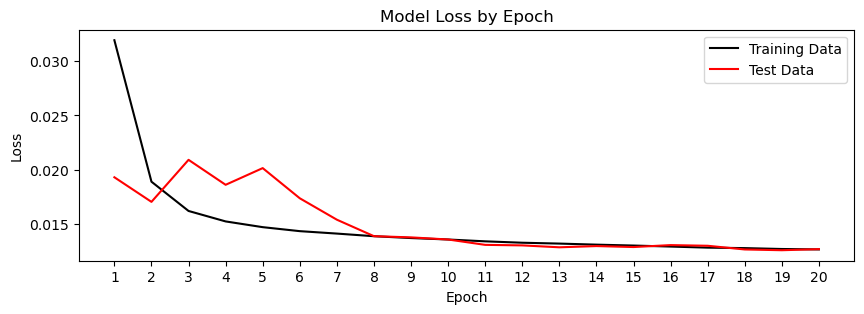

In [43]:
fig, ax = plt.subplots(figsize=(10,3))
plt.title(label='Model Loss by Epoch', loc='center')
ax.plot(history.history['loss'], label='Training Data', color='black')
ax.plot(history.history['val_loss'], label='Test Data', color='red')
ax.set(xlabel='Epoch', ylabel='Loss')
plt.xticks(ticks=np.arange(len(history.history['loss'])), labels=np.arange(1, len(history.history['loss'])+1))
plt.legend()
plt.show()

# Predecir

In [44]:
X_test_denoised = model.predict(X_test_noisy).reshape(10000, 28, 28)

313/313 [==============================] - 2s 5ms/step


In [45]:
# Volver a aplicar reshape al X_test_noisy para graficar las imágenes de 28 x 28
X_test_noisy_reshaped = X_test_noisy.reshape(10000, 28, 28)

In [46]:
# Volver a aplicar reshape al X_test para graficar las imágenes de 28 x 28
X_test_reshaped = X_test.reshape(10000, 28, 28)

# Visualizar algunos resultados

In [94]:
def plot_denoised(n_digits):
    fig = plt.figure(figsize=(2*n_digits, 5))  # Dimensiones de la figura
    
    for i in range(n_digits):
        # Imagen original en la primera columna
        ax = fig.add_subplot(3, n_digits, i + 1, xticks=[], yticks=[])
        ax.imshow(X_test_reshaped[i], cmap=plt.cm.binary)
        if i == 0:
            ax.text(-0.2, 0.5, "Original", fontsize=12, va='center', ha='right', transform=ax.transAxes)

        # Imagen ruidosa en la segunda columna
        ax = fig.add_subplot(3, n_digits, i + 1 + n_digits, xticks=[], yticks=[])
        ax.imshow(X_test_noisy_reshaped[i], cmap=plt.cm.binary)
        if i == 0:
            ax.text(-0.2, 0.5, "Noisy", fontsize=12, va='center', ha='right', transform=ax.transAxes)

        # Imagen denoised en la tercera columna
        ax = fig.add_subplot(3, n_digits, i + 1 + 2 * n_digits, xticks=[], yticks=[])
        ax.imshow(X_test_denoised[i], cmap=plt.cm.binary)
        if i == 0:
            ax.text(-0.2, 0.5, "Denoised", fontsize=12, va='center', ha='right', transform=ax.transAxes)

    plt.tight_layout()  # Ajustar el layout para evitar solapamientos
    plt.show()  # Mostrar la figura

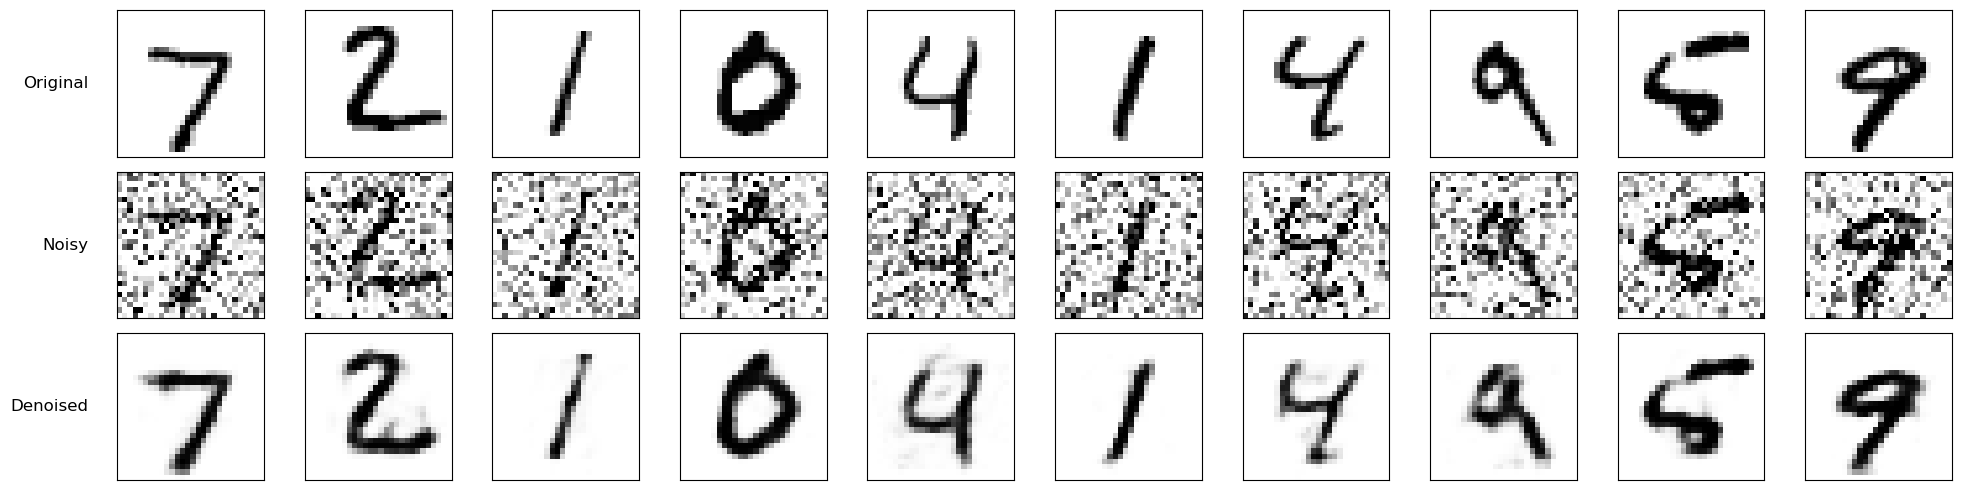

In [95]:
plot_denoised(10)